## importing libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

## Step 1: Data Loading & Understanding The Data

In [2]:
import pandas as pd

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.shape

(7043, 21)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [5]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [7]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df["Churn"].value_counts()

,count
Churn,
No,5174
Yes,1869


In [10]:
df["Churn"].value_counts(normalize=True) * 100

,proportion
Churn,
No,73.463013
Yes,26.536987


## Step 2: Data Cleaning

In [11]:
df["TotalCharges"].dtype

dtype('O')

In [12]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

In [13]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [14]:
df[df["TotalCharges"].isnull()]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [15]:
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())

In [16]:
df.duplicated().sum()

np.int64(0)

In [17]:
df.drop_duplicates(inplace=True)

In [18]:
df.drop("customerID", axis=1, inplace=True)

In [19]:
df.shape

(7043, 20)

In [20]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2281.916928
std,0.368612,24.559481,30.090047,2265.270398
min,0.000000,0.000000,18.250000,18.800000
25%,0.000000,9.000000,35.500000,402.225000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


In [22]:
df.isnull().sum()

,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0
OnlineBackup,0


## Step 3: EDA (Exploratory Data Analysis)

In [23]:
df["Churn"].value_counts()

,count
Churn,
No,5174
Yes,1869


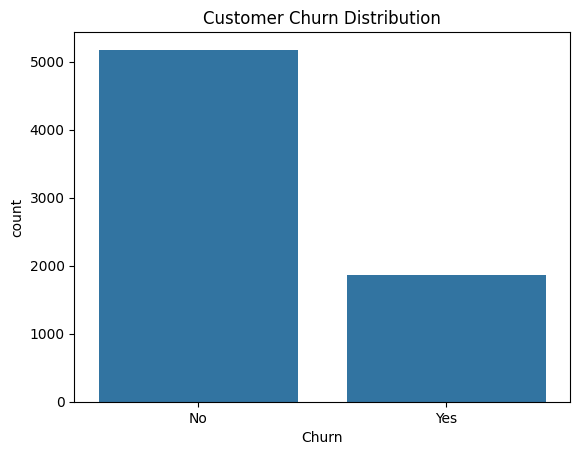

In [24]:
sns.countplot(x="Churn", data=df)
plt.title("Customer Churn Distribution")
plt.show()

In [25]:
df["Churn"].value_counts(normalize=True) * 100

,proportion
Churn,
No,73.463013
Yes,26.536987


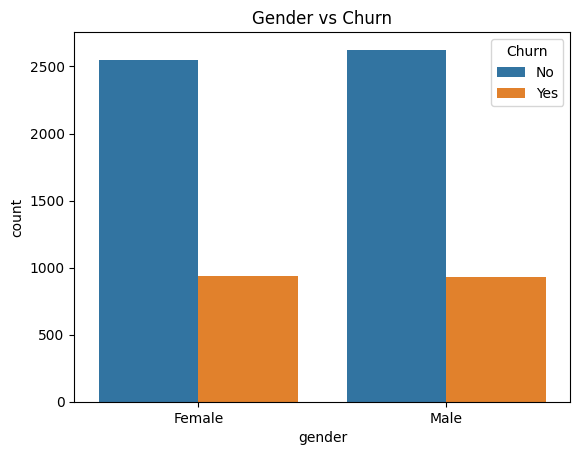

In [26]:
sns.countplot(x="gender", hue="Churn", data=df)
plt.title("Gender vs Churn")
plt.show()

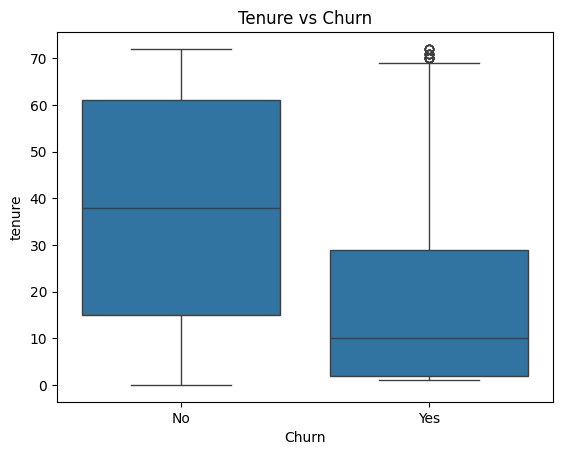

In [27]:
sns.boxplot(x="Churn", y="tenure", data=df)
plt.title("Tenure vs Churn")
plt.show()

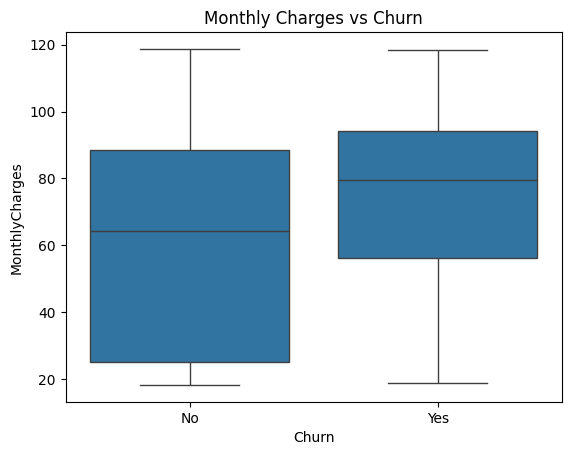

In [28]:
sns.boxplot(x="Churn", y="MonthlyCharges", data=df)
plt.title("Monthly Charges vs Churn")
plt.show()

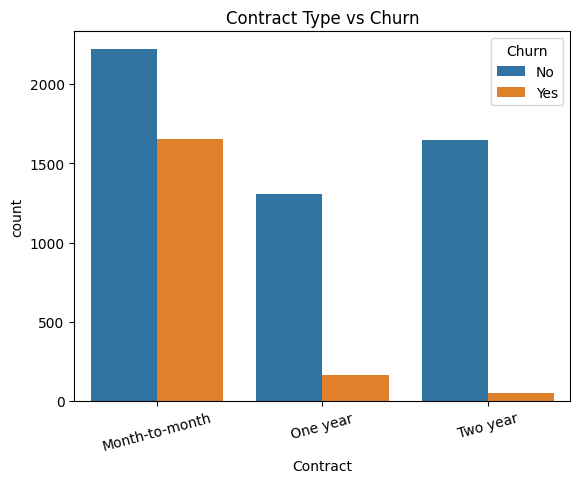

In [29]:
sns.countplot(x="Contract", hue="Churn", data=df)
plt.title("Contract Type vs Churn")
plt.xticks(rotation=15)
plt.show()

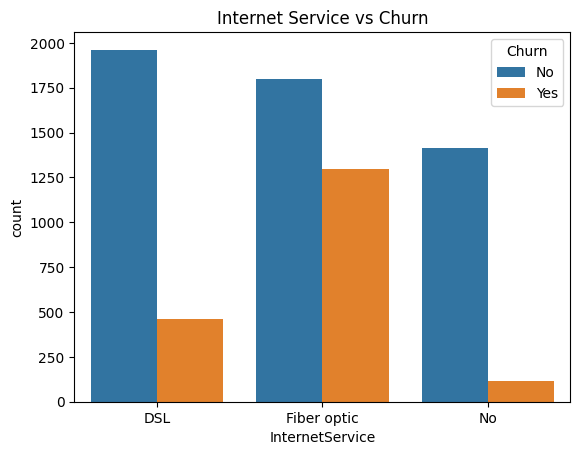

In [30]:
sns.countplot(x="InternetService", hue="Churn", data=df)
plt.title("Internet Service vs Churn")
plt.show()

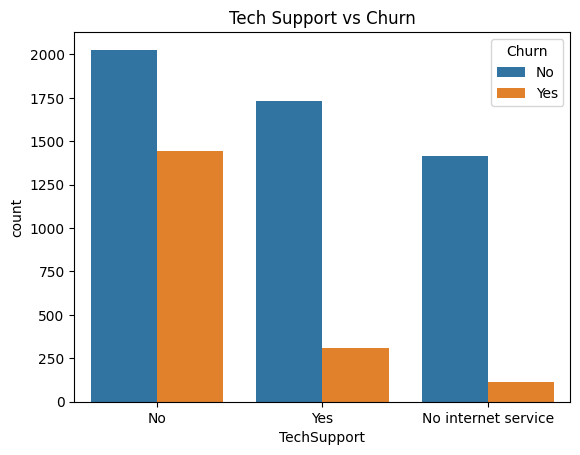

In [31]:
sns.countplot(x="TechSupport", hue="Churn", data=df)
plt.title("Tech Support vs Churn")
plt.show()

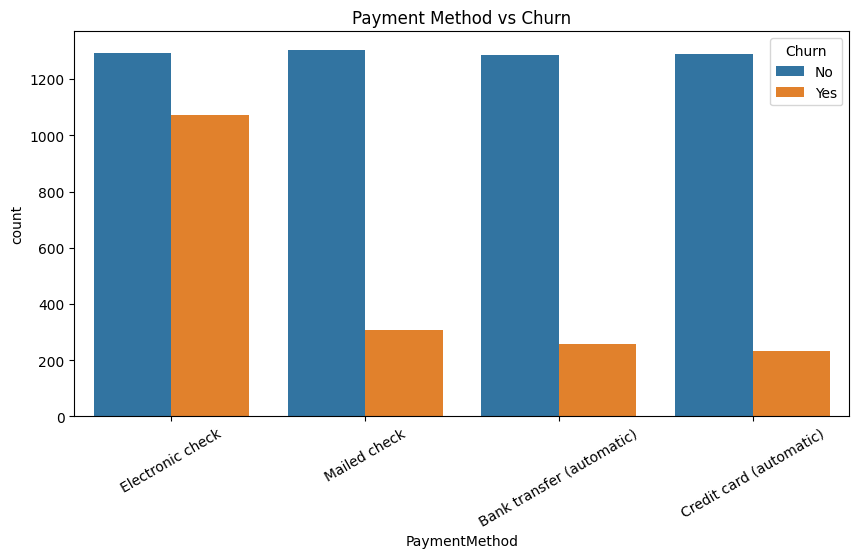

In [32]:
plt.figure(figsize=(10,5))

sns.countplot(
    x="PaymentMethod",
    hue="Churn",
    data=df
)

plt.title("Payment Method vs Churn")
plt.xticks(rotation=30)
plt.show()

In [33]:
numeric_cols = df.select_dtypes(include="number")

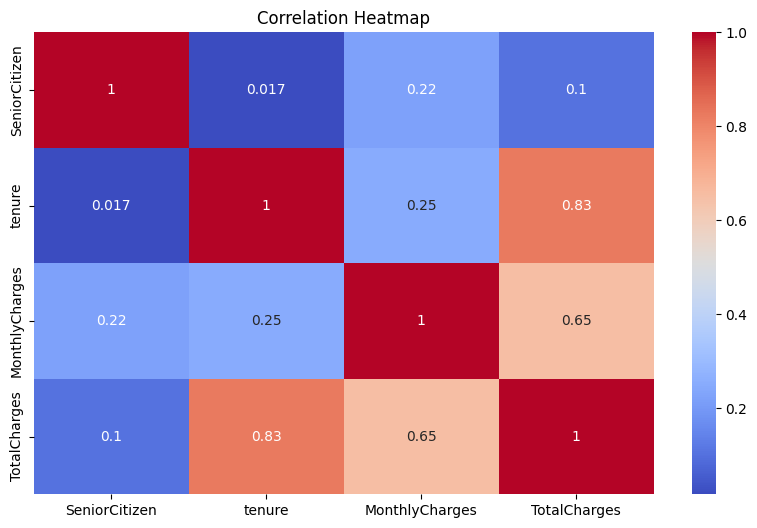

In [34]:
plt.figure(figsize=(10,6))

sns.heatmap(
    numeric_cols.corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")
plt.show()

## Step 4 — Feature Engineering & Preprocessing

In [35]:
X = df.drop("Churn", axis=1)
y = df["Churn"]

In [36]:
X.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65


In [37]:
y.head()

,Churn
0,No
1,No
2,Yes
3,No
4,Yes


In [38]:
y = y.map({
    "Yes": 1,
    "No": 0
})

In [39]:
y.value_counts()

,count
Churn,
0,5174
1,1869


In [40]:
categorical_cols = X.select_dtypes(
    include="object"
).columns

categorical_cols

Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='object')

In [41]:
numerical_cols = X.select_dtypes(
    include="number"
).columns

numerical_cols

Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object')

In [42]:
X = pd.get_dummies(
    X,
    columns=categorical_cols,
    drop_first=True
)

In [43]:
X.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,False,True,False,False,True,False,...,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,True,False,False,True,False,False,...,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,True,False,False,True,False,False,...,False,False,False,False,False,False,True,False,False,True
3,0,45,42.30,1840.75,True,False,False,False,True,False,...,False,False,False,False,True,False,False,False,False,False
4,0,2,70.70,151.65,False,False,False,True,False,False,...,False,False,False,False,False,False,True,False,True,False


In [44]:
X.shape

(7043, 30)

In [45]:
X.dtypes.value_counts()

,count
bool,26
int64,2
float64,2


In [46]:
# Convert only boolean columns to integers

bool_columns = X.select_dtypes(include=["bool"]).columns

X[bool_columns] = X[bool_columns].astype(int)

print("Boolean columns converted:", len(bool_columns))
print("\nData types:")
print(X.dtypes.value_counts())

print("\nProcessed data:")
display(X.head())

Boolean columns converted: 26

Data types:
int64      28
float64     2
Name: count, dtype: int64

Processed data:


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,1,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,1,0,0,1,0,0,...,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,0,0,1,0,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,1,0,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,0,0,0,1,0,0,...,0,0,0,0,0,0,1,0,1,0


## step 5: Train-Test Split

In [47]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [48]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (5634, 30)
X_test: (1409, 30)
y_train: (5634,)
y_test: (1409,)


In [49]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [50]:
print(X_train_scaled.shape)
print(X_test_scaled.shape)

(5634, 30)
(1409, 30)


In [51]:
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

Churn
0    0.734647
1    0.265353
Name: proportion, dtype: float64
Churn
0    0.734564
1    0.265436
Name: proportion, dtype: float64


## step 6: Model Training Logistic Regression

In [52]:
from sklearn.linear_model import LogisticRegression

In [53]:
lr = LogisticRegression(max_iter=1000)

lr.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000)

In [54]:
lr_pred = lr.predict(X_test_scaled)

In [55]:
from sklearn.metrics import accuracy_score

lr_accuracy = accuracy_score(y_test, lr_pred)

print("Logistic Regression Accuracy:", lr_accuracy)

Logistic Regression Accuracy: 0.8069552874378992


In [56]:
lr_pred[:10]

array([0, 1, 0, 0, 0, 1, 0, 0, 0, 0])

In [57]:
from sklearn.metrics import classification_report

print(classification_report(y_test, lr_pred))

              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.57      0.61       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



In [58]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, lr_pred)

print(cm)

[[925 110]
 [162 212]]


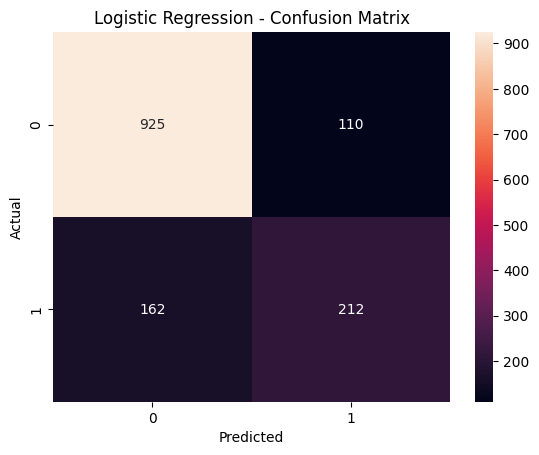

In [59]:
sns.heatmap(cm, annot=True, fmt="d")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Confusion Matrix")

plt.show()

In [60]:
lr_accuracy = accuracy_score(y_test, lr_pred)

## Decision Tree

In [61]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(
    random_state=42
)

dt.fit(X_train, y_train)

dt_pred = dt.predict(X_test)

In [62]:
from sklearn.metrics import accuracy_score

dt_accuracy = accuracy_score(y_test, dt_pred)

print("Decision Tree Accuracy:", dt_accuracy)

Decision Tree Accuracy: 0.7416607523066004


In [63]:
from sklearn.metrics import classification_report

print(classification_report(y_test, dt_pred))

              precision    recall  f1-score   support

           0       0.82      0.83      0.83      1035
           1       0.51      0.49      0.50       374

    accuracy                           0.74      1409
   macro avg       0.67      0.66      0.66      1409
weighted avg       0.74      0.74      0.74      1409



In [64]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, dt_pred)

print(cm)

[[860 175]
 [189 185]]


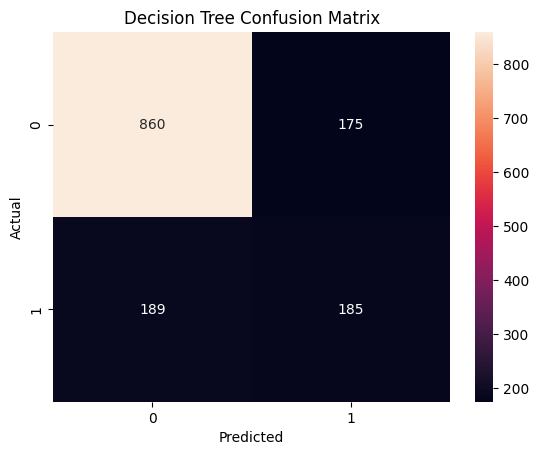

In [65]:
sns.heatmap(cm, annot=True, fmt="d")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Decision Tree Confusion Matrix")

plt.show()

## Random Forest

In [66]:
from sklearn.ensemble import RandomForestClassifier

In [67]:
rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

In [68]:
rf.fit(X_train, y_train)

RandomForestClassifier(n_estimators=200, random_state=42)

In [69]:
rf_pred = rf.predict(X_test)

In [70]:
from sklearn.metrics import accuracy_score

rf_accuracy = accuracy_score(y_test, rf_pred)

print("Random Forest Accuracy:", rf_accuracy)

Random Forest Accuracy: 0.7899219304471257


In [71]:
from sklearn.metrics import classification_report

print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

           0       0.83      0.90      0.86      1035
           1       0.63      0.49      0.56       374

    accuracy                           0.79      1409
   macro avg       0.73      0.70      0.71      1409
weighted avg       0.78      0.79      0.78      1409



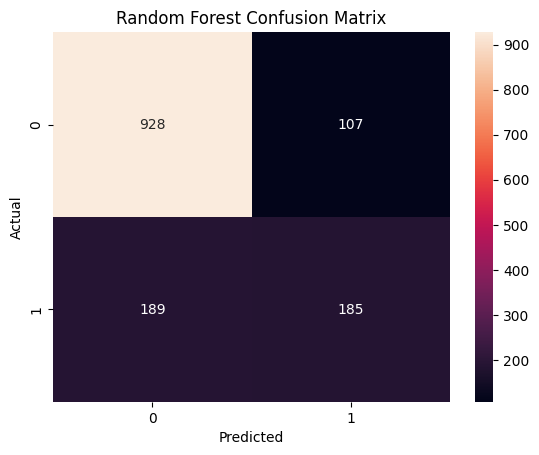

In [72]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, rf_pred)

sns.heatmap(cm, annot=True, fmt="d")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")

plt.show()

## K-Nearest Neighbors (KNN)


In [73]:
from sklearn.neighbors import KNeighborsClassifier

In [74]:
knn = KNeighborsClassifier(
    n_neighbors=5
)

In [75]:
knn.fit(X_train_scaled, y_train)

KNeighborsClassifier()

In [76]:
knn_pred = knn.predict(X_test_scaled)

In [77]:
knn_accuracy = accuracy_score(y_test, knn_pred)

print("KNN Accuracy:", knn_accuracy)

KNN Accuracy: 0.7473385379701917


In [78]:
print(classification_report(y_test, knn_pred))

              precision    recall  f1-score   support

           0       0.82      0.84      0.83      1035
           1       0.53      0.50      0.51       374

    accuracy                           0.75      1409
   macro avg       0.67      0.67      0.67      1409
weighted avg       0.74      0.75      0.75      1409



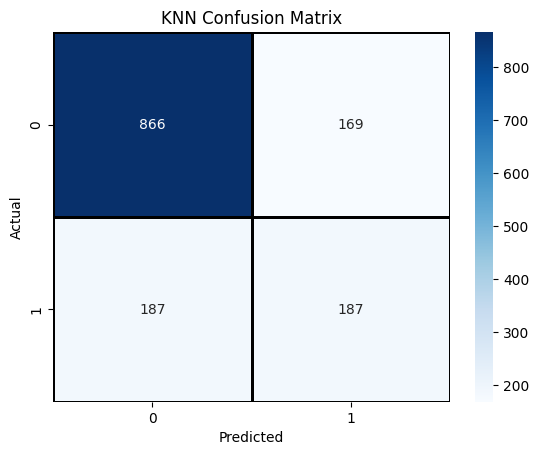

In [79]:
cm = confusion_matrix(y_test, knn_pred)

sns.heatmap(cm, annot=True, fmt="d",cmap="Blues",linewidths=1,linecolor="black")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("KNN Confusion Matrix")

plt.show()

## Model Comparison table

In [80]:
lr_accuracy = accuracy_score(y_test, lr_pred)
dt_accuracy = accuracy_score(y_test, dt_pred)
rf_accuracy = accuracy_score(y_test, rf_pred)
knn_accuracy = accuracy_score(y_test, knn_pred)

In [81]:
model_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "KNN"
    ],
    "Accuracy": [
        lr_accuracy,
        dt_accuracy,
        rf_accuracy,
        knn_accuracy
    ]
})

model_results

,Model,Accuracy
0,Logistic Regression,0.806955
1,Decision Tree,0.741661
2,Random Forest,0.789922
3,KNN,0.747339


In [82]:
from sklearn.metrics import precision_score, recall_score, f1_score

results = []

models = {
    "Logistic Regression": lr_pred,
    "Decision Tree": dt_pred,
    "Random Forest": rf_pred,
    "KNN": knn_pred
}

for name, pred in models.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1 Score": f1_score(y_test, pred)
    })

comparison_df = pd.DataFrame(results)

comparison_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.806955,0.658385,0.566845,0.609195
1,Decision Tree,0.741661,0.513889,0.494652,0.504087
2,Random Forest,0.789922,0.633562,0.494652,0.555556
3,KNN,0.747339,0.525281,0.500000,0.512329


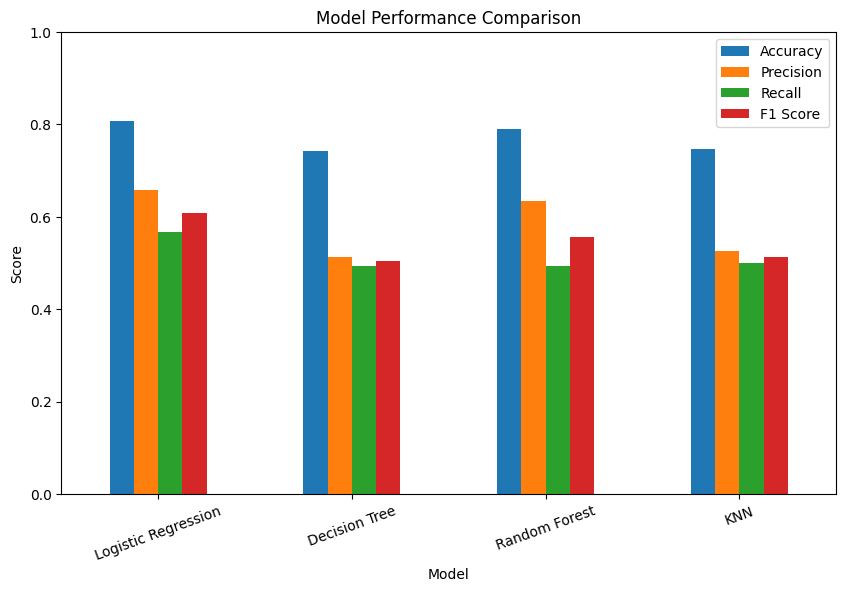

In [83]:
comparison_df.set_index("Model").plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=20)
plt.ylim(0, 1)
plt.show()

## Step 7: ROC-AUC Curve

In [84]:
lr_prob = lr.predict_proba(X_test_scaled)[:, 1]
dt_prob = dt.predict_proba(X_test)[:, 1]
rf_prob = rf.predict_proba(X_test)[:, 1]
knn_prob = knn.predict_proba(X_test_scaled)[:, 1]

In [85]:
from sklearn.metrics import roc_auc_score

print("Logistic Regression:", roc_auc_score(y_test, lr_prob))
print("Decision Tree:", roc_auc_score(y_test, dt_prob))
print("Random Forest:", roc_auc_score(y_test, rf_prob))
print("KNN:", roc_auc_score(y_test, knn_prob))

Logistic Regression: 0.8415846443979436
Decision Tree: 0.6622968818620992
Random Forest: 0.826492546952905
KNN: 0.7716035030613035


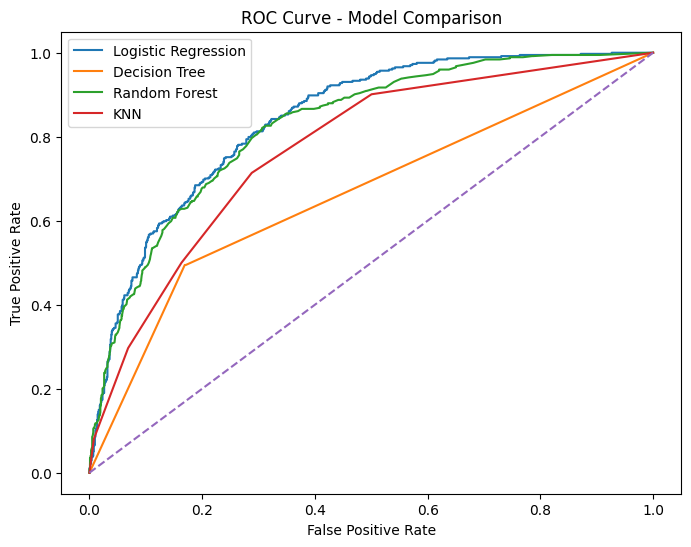

In [86]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

lr_fpr, lr_tpr, _ = roc_curve(y_test, lr_prob)
dt_fpr, dt_tpr, _ = roc_curve(y_test, dt_prob)
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_prob)
knn_fpr, knn_tpr, _ = roc_curve(y_test, knn_prob)

plt.figure(figsize=(8, 6))

plt.plot(lr_fpr, lr_tpr, label="Logistic Regression")
plt.plot(dt_fpr, dt_tpr, label="Decision Tree")
plt.plot(rf_fpr, rf_tpr, label="Random Forest")
plt.plot(knn_fpr, knn_tpr, label="KNN")

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Model Comparison")
plt.legend()
plt.show()

## Find the important Features

In [87]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(15)

,Feature,Importance
3,TotalCharges,0.194123
1,tenure,0.171364
2,MonthlyCharges,0.167562
10,InternetService_Fiber optic,0.038864
28,PaymentMethod_Electronic check,0.038285
25,Contract_Two year,0.031477
4,gender_Male,0.028519
13,OnlineSecurity_Yes,0.027796
26,PaperlessBilling_Yes,0.025725
5,Partner_Yes,0.023285


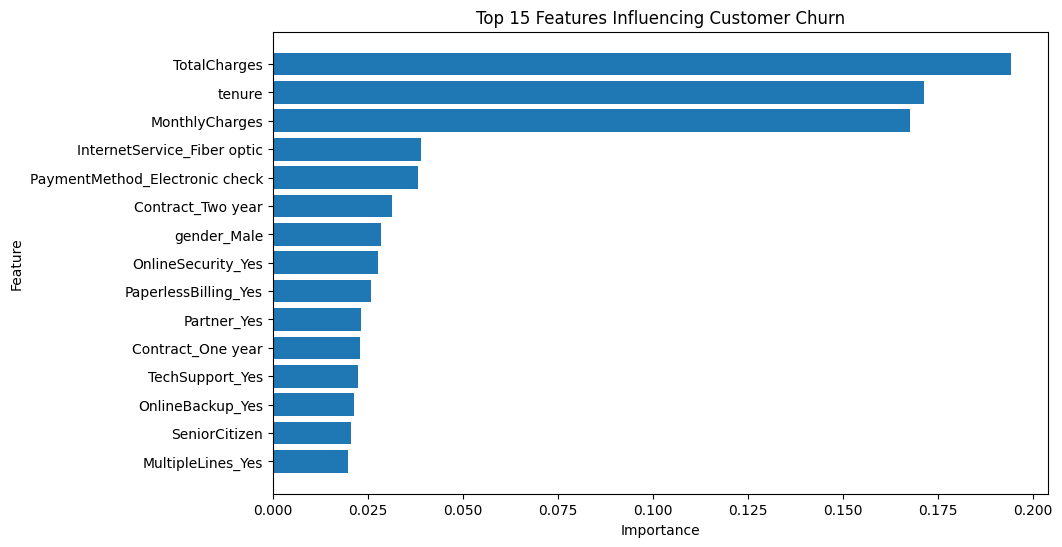

In [88]:
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"].head(15)[::-1],
    feature_importance["Importance"].head(15)[::-1]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 15 Features Influencing Customer Churn")
plt.show()

## Customer Churn Probability

In [89]:
churn_probability = rf.predict_proba(X_test)[:, 1]

probability_df = pd.DataFrame({
    "Actual_Churn": y_test.values,
    "Churn_Probability": churn_probability
})

probability_df.head(10)

,Actual_Churn,Churn_Probability
0,0,0.000
1,0,0.750
2,0,0.085
3,0,0.290
4,0,0.015
5,0,0.395
6,0,0.380
7,0,0.070
8,0,0.005
9,1,0.475


In [90]:
probability_df["Churn_Probability"] = (
    probability_df["Churn_Probability"] * 100
).round(2)

probability_df.head(10)

,Actual_Churn,Churn_Probability
0,0,0.0
1,0,75.0
2,0,8.5
3,0,29.0
4,0,1.5
5,0,39.5
6,0,38.0
7,0,7.0
8,0,0.5
9,1,47.5


| Step                               | |
| ---------------------------------- | ------ |
| 1. Load Dataset                    |      |
| 2. Understand Dataset              |      |
| 3. Data Cleaning                   |       |
| 4. Exploratory Data Analysis (EDA) |       |
| 5. Feature & Target Separation     |        |
| 6. Encoding Categorical Data       |      |
| 7. Train-Test Split                |        |
| 8. Feature Scaling                 |        |
| 9. Logistic Regression             |        |
| 10. Decision Tree                  |        |
| 11. Random Forest                  |        |
| 12. KNN                            |     |
| 13. Model Evaluation               |       |
| 14. Model Comparison               |       |
| 15. ROC-AUC / ROC Curve            |       |
| 16. Feature Importance             |       |
| 17. Churn Probability              |       |


In [91]:
# Step 18: Customer Risk Segmentation

def classify_churn_risk(probability):
    if probability < 0.30:
        return "Low Risk"
    elif probability < 0.60:
        return "Medium Risk"
    else:
        return "High Risk"

In [96]:

# Step 18: Customer Risk Segmentation

def classify_churn_risk(probability):
    if probability < 0.30:
        return "Low Risk"
    elif probability < 0.60:
        return "Medium Risk"
    else:
        return "High Risk"


# Create a copy of the existing probability DataFrame
risk_df = probability_df.copy()

# Assign risk categories
risk_df["Risk_Category"] = risk_df["Churn_Probability"].apply(
    classify_churn_risk
)

# Display the first 10 customers
print("Customer Risk Segmentation Completed!\n")
display(risk_df.head(10))

# Display the number of customers in each risk category
print("\nRisk Category Distribution:")
display(risk_df["Risk_Category"].value_counts())

# Calculate risk category percentages
print("\nRisk Category Percentage:")
display(
    (risk_df["Risk_Category"].value_counts(normalize=True) * 100)
    .round(2)
)


Customer Risk Segmentation Completed!



,Actual_Churn,Churn_Probability,Risk_Category
0,0,0.0,Low Risk
1,0,75.0,High Risk
2,0,8.5,High Risk
3,0,29.0,High Risk
4,0,1.5,High Risk
5,0,39.5,High Risk
6,0,38.0,High Risk
7,0,7.0,High Risk
8,0,0.5,Medium Risk
9,1,47.5,High Risk



Risk Category Distribution:


,count
Risk_Category,
High Risk,1258
Low Risk,100
Medium Risk,51



Risk Category Percentage:


,proportion
Risk_Category,
High Risk,89.28
Low Risk,7.10
Medium Risk,3.62


### Retention Recommendation System





In [97]:

# Step 19: Retention Recommendation System

def recommend_retention_action(risk_category):

    if risk_category == "Low Risk":
        return "Maintain loyalty benefits and regular engagement"

    elif risk_category == "Medium Risk":
        return "Offer personalized discounts and monitor satisfaction"

    else:
        return "Prioritize customer support and provide a retention offer"


# Create a copy of the risk DataFrame
recommendation_df = risk_df.copy()

# Generate retention recommendations
recommendation_df["Retention_Recommendation"] = (
    recommendation_df["Risk_Category"]
    .apply(recommend_retention_action)
)

# Display customer-level recommendations
print("Retention Recommendation System Completed!\n")

display(recommendation_df.head(10))


Retention Recommendation System Completed!



,Actual_Churn,Churn_Probability,Risk_Category,Retention_Recommendation
0,0,0.0,Low Risk,Maintain loyalty benefits and regular engagement
1,0,75.0,High Risk,Prioritize customer support and provide a rete...
2,0,8.5,High Risk,Prioritize customer support and provide a rete...
3,0,29.0,High Risk,Prioritize customer support and provide a rete...
4,0,1.5,High Risk,Prioritize customer support and provide a rete...
5,0,39.5,High Risk,Prioritize customer support and provide a rete...
6,0,38.0,High Risk,Prioritize customer support and provide a rete...
7,0,7.0,High Risk,Prioritize customer support and provide a rete...
8,0,0.5,Medium Risk,Offer personalized discounts and monitor satis...
9,1,47.5,High Risk,Prioritize customer support and provide a rete...


In [98]:


recommendation_summary = (
    recommendation_df.groupby(
        ["Risk_Category", "Retention_Recommendation"]
    )
    .size()
    .reset_index(name="Customer_Count")
)

display(recommendation_summary)

,Risk_Category,Retention_Recommendation,Customer_Count
0,High Risk,Prioritize customer support and provide a rete...,1258
1,Low Risk,Maintain loyalty benefits and regular engagement,100
2,Medium Risk,Offer personalized discounts and monitor satis...,51


### Business Insights & Analytics

In [99]:

#Business Insights & Analytics

total_customers = len(recommendation_df)

high_risk_customers = (
    recommendation_df["Risk_Category"] == "High Risk"
).sum()

medium_risk_customers = (
    recommendation_df["Risk_Category"] == "Medium Risk"
).sum()

low_risk_customers = (
    recommendation_df["Risk_Category"] == "Low Risk"
).sum()

high_risk_percentage = (
    high_risk_customers / total_customers * 100
    if total_customers > 0 else 0
)

actual_churn_rate = (
    recommendation_df["Actual_Churn"].mean() * 100
    if total_customers > 0 else 0
)

print("=" * 45)
print("       CUSTOMER CHURN BUSINESS SUMMARY")
print("=" * 45)

print(f"Total Customers Analyzed : {total_customers}")
print(f"High-Risk Customers      : {high_risk_customers}")
print(f"Medium-Risk Customers    : {medium_risk_customers}")
print(f"Low-Risk Customers       : {low_risk_customers}")
print(f"High-Risk Percentage     : {high_risk_percentage:.2f}%")
print(f"Actual Churn Rate        : {actual_churn_rate:.2f}%")

print("=" * 45)




       CUSTOMER CHURN BUSINESS SUMMARY
Total Customers Analyzed : 1409
High-Risk Customers      : 1258
Medium-Risk Customers    : 51
Low-Risk Customers       : 100
High-Risk Percentage     : 89.28%
Actual Churn Rate        : 26.54%


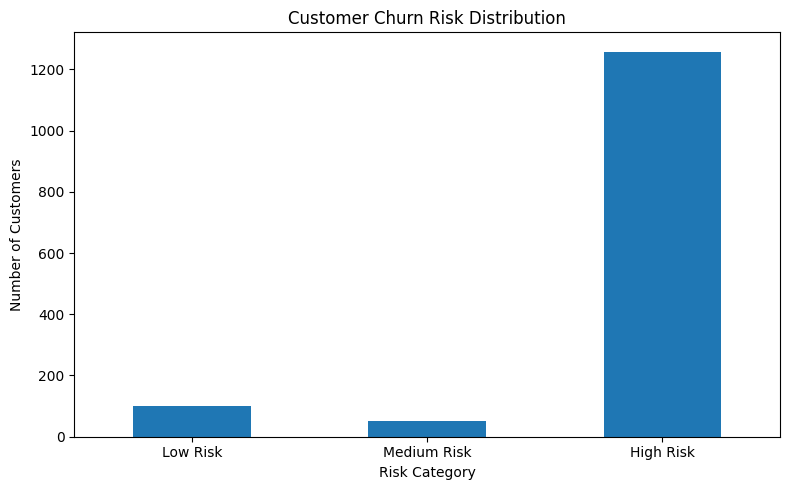

In [100]:
import matplotlib.pyplot as plt

risk_counts = recommendation_df["Risk_Category"].value_counts()

# Display risk distribution
plt.figure(figsize=(8, 5))
risk_counts.reindex(
    ["Low Risk", "Medium Risk", "High Risk"],
    fill_value=0
).plot(kind="bar")

plt.title("Customer Churn Risk Distribution")
plt.xlabel("Risk Category")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [101]:
recommendation_summary = (
    recommendation_df.groupby("Risk_Category")
    ["Retention_Recommendation"]
    .value_counts()
    .rename("Customer_Count")
    .reset_index()
)

display(recommendation_summary)

,Risk_Category,Retention_Recommendation,Customer_Count
0,High Risk,Prioritize customer support and provide a rete...,1258
1,Low Risk,Maintain loyalty benefits and regular engagement,100
2,Medium Risk,Offer personalized discounts and monitor satis...,51


In [102]:
%pip install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 25.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 48.1 MB/s eta 0:00:00


In [103]:
import streamlit as st

print("Streamlit installed successfully!")
print("Streamlit version:", st.__version__)

Streamlit installed successfully!
Streamlit version: 1.66.0


In [104]:

import joblib

# Save the trained Random Forest model
joblib.dump(rf, "random_forest_model.pkl")

print("Random Forest model saved successfully!")


Random Forest model saved successfully!


In [105]:
import os

if os.path.exists("random_forest_model.pkl"):
    print("Model file exists!")
    print("File size:", round(
        os.path.getsize("random_forest_model.pkl") / 1024, 2
    ), "KB")
else:
    print("Model file not found!")

Model file exists!
File size: 37130.04 KB


In [106]:

# Corrected Customer Risk Segmentation
# Churn_Probability is already expressed as a percentage (0-100)

def classify_churn_risk(probability):
    if probability < 30:
        return "Low Risk"
    elif probability < 60:
        return "Medium Risk"
    else:
        return "High Risk"


# Recreate risk categories using the correct thresholds
risk_df = probability_df.copy()

risk_df["Risk_Category"] = (
    risk_df["Churn_Probability"].apply(classify_churn_risk)
)

print("Corrected Customer Risk Segmentation\n")

display(risk_df.head(10))

print("\nRisk Category Distribution:")
display(risk_df["Risk_Category"].value_counts())

print("\nRisk Category Percentage:")
display(
    (
        risk_df["Risk_Category"].value_counts(normalize=True) * 100
    ).round(2)
)

Corrected Customer Risk Segmentation



,Actual_Churn,Churn_Probability,Risk_Category
0,0,0.0,Low Risk
1,0,75.0,High Risk
2,0,8.5,Low Risk
3,0,29.0,Low Risk
4,0,1.5,Low Risk
5,0,39.5,Medium Risk
6,0,38.0,Medium Risk
7,0,7.0,Low Risk
8,0,0.5,Low Risk
9,1,47.5,Medium Risk



Risk Category Distribution:


,count
Risk_Category,
Low Risk,890
Medium Risk,304
High Risk,215



Risk Category Percentage:


,proportion
Risk_Category,
Low Risk,63.17
Medium Risk,21.58
High Risk,15.26


In [107]:
# Update retention recommendations

def recommend_retention_action(risk_category):

    if risk_category == "Low Risk":
        return "Maintain loyalty benefits and regular engagement"

    elif risk_category == "Medium Risk":
        return "Offer personalized discounts and monitor satisfaction"

    else:
        return "Prioritize customer support and provide a retention offer"


recommendation_df = risk_df.copy()

recommendation_df["Retention_Recommendation"] = (
    recommendation_df["Risk_Category"]
    .apply(recommend_retention_action)
)

print("Updated Retention Recommendations\n")
display(recommendation_df.head(10))

print("\nUpdated Recommendation Summary:")
display(
    recommendation_df["Risk_Category"].value_counts()
)

Updated Retention Recommendations



,Actual_Churn,Churn_Probability,Risk_Category,Retention_Recommendation
0,0,0.0,Low Risk,Maintain loyalty benefits and regular engagement
1,0,75.0,High Risk,Prioritize customer support and provide a rete...
2,0,8.5,Low Risk,Maintain loyalty benefits and regular engagement
3,0,29.0,Low Risk,Maintain loyalty benefits and regular engagement
4,0,1.5,Low Risk,Maintain loyalty benefits and regular engagement
5,0,39.5,Medium Risk,Offer personalized discounts and monitor satis...
6,0,38.0,Medium Risk,Offer personalized discounts and monitor satis...
7,0,7.0,Low Risk,Maintain loyalty benefits and regular engagement
8,0,0.5,Low Risk,Maintain loyalty benefits and regular engagement
9,1,47.5,Medium Risk,Offer personalized discounts and monitor satis...



Updated Recommendation Summary:


,count
Risk_Category,
Low Risk,890
Medium Risk,304
High Risk,215


In [108]:
import joblib

# Save the model together with its feature-column names
model_bundle = {
    "model": rf,
    "feature_columns": list(X.columns)
}

joblib.dump(model_bundle, "churn_model_bundle.pkl")

print("Model bundle saved successfully!")
print("Number of features:", len(model_bundle["feature_columns"]))
print("Saved file: churn_model_bundle.pkl")

Model bundle saved successfully!
Number of features: 30
Saved file: churn_model_bundle.pkl


In [110]:
import os

file_name = "churn_model_bundle.pkl"

if os.path.exists(file_name):
    print("Model bundle is ready!")
    print("File size:", round(os.path.getsize(file_name) / 1024, 2), "KB")
else:
    print("Model bundle not found!")

Model bundle is ready!
File size: 37130.77 KB


In [111]:
from google.colab import files

files.download("churn_model_bundle.pkl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>